In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sys import stdin
import math

# Exercise 1

In [2]:
# Purpose: Calculate area using trapezoidal rule.
# Input: a, b, n
# Output: estimate of area between x-axis, x = a, x = b
# using n trapezoids.
# Usage: python Trapez.py
# Note: The function f(x) is hardwired.
# Function: f
# Purpose: Compute value of function to be integrated
# Input args: x (double)
# Return val: f(x) (double)

def f(x):
    return_val = math.sin(x)
    return return_val

# End of f

# Function: Trap
# Purpose: Estimate area using the trapezoidal rule
# Input args: a: left endpoint (double)
# b: right endpoint (double)
# n: number of trapezoids (int)
# h: stepsize = length of base of trapezoids (double)
# Return val: Trapezoidal rule estimate of area between x-axis,

def Trap(a, b, n, h):
    area = (f(a) + f(b))/2.0
    for i in range(1, n):
        x = a + i*h;
        area = area + f(x)
    area = area*h
    Error = 1 - area
    return area, Error

# End of Trap

In [3]:
a = 0. # lower bound of integration interval
b = .5*math.pi # upper bound of integration interval
n = 256 # number of intervals
h = (b-a)/(n) # The correction lies here - we change (n - 1) to n
area, Error = Trap(a, b, n, h)
#print("With n =", n, "intervals, our trapezoid estimate")
#print("Area from", a, "to", b, "= %.15f" % area)
print(area, Error)

0.9999968625352881 3.137464711922e-06


In [4]:
# Defining an array for the number of subintervals
n_arr = np.array([1, 2, 4, 8, 16, 32, 64, 128, 256])

# Defining an array of the corresponding step size
h_arr = np.zeros_like(n_arr, dtype = float)

# Initializing the computation arrays
area_arr = np.zeros_like(n_arr, dtype = float)
Err_arr = np.zeros_like(n_arr, dtype = float)
Ratio_arr = np.zeros(len(n_arr) - 1, dtype = float)

# Computations
for i in range(len(n_arr)): # Computing the step lengths, areas and corresponding errors; assigning values to the corresponding arrays
    h_arr[i] = (b - a) / (n_arr[i])
    area_arr[i], Err_arr[i] = Trap(a, b, n_arr[i], h_arr[i])

for i in range(len(n_arr) - 1): # Computing the ratio of errors
    Ratio_arr[i] = Err_arr[i] / Err_arr[i + 1]
    

print(area_arr, Err_arr, Ratio_arr)

[0.78539816 0.94805945 0.9871158  0.99678517 0.99919668 0.99979919
 0.9999498  0.99998745 0.99999686] [2.14601837e-01 5.19405510e-02 1.28841990e-02 3.21482811e-03
 8.03319515e-04 2.00805680e-04 5.01999079e-05 1.25498825e-05
 3.13746471e-06] [4.13168194 4.03133722 4.00774118 4.00192956 4.00048203 4.00012049
 4.00003012 4.00000753]


# Exercise 2

In [5]:
# Redefined the Trapez function to perform Simpson integration
def Simpson(a, b, n, h):
    """
    a: lower bound of integral
    b: upper bound of integral
    n: number of sub-intervals
    h: step-length
    """
    area = (f(a) + f(b))/3.0 # weight factors of first and last points
    
    for i in range(1, n):
        x = a + i * h # x-grid stepping
        
        if (i % 2 == 0): # Condition to find even points of the x-grid
            area = area + f(x) * 2 / 3 # weight factors of even grid points
        else:
            area = area + f(x) * 4 / 3 # weight factors of odd grid points
            
    area = area * h # updating area
    Error = 2 - area # error compared to true value of integral
    return area, Error

In [6]:
a2 = 0. # lower bound of integration interval
b2 = math.pi # upper bound of integration interval
n2 = 256 # number of intervals
h2 = (b-a)/(n)
area2, Error2 = Simpson(a2, b2, n2, h2)
print(area2, Error2)

0.9979546922906939 1.002045307709306


In [7]:
# Defining an array for the number of subintervals
n_arr2 = np.array([2, 4, 8, 16, 32, 64, 128, 256])

# Defining an array of the corresponding step size
h_arr2 = np.zeros_like(n_arr2, dtype = float)

# Initializing the computation arrays
area_arr2 = np.zeros_like(n_arr2, dtype = float)
Err_arr2 = np.zeros_like(n_arr2, dtype = float)
Ratio_arr2 = np.zeros(len(n_arr2) - 1, dtype = float)

# Computations
for i in range(len(n_arr2)): # Computing the step lengths, areas and corresponding errors; assigning values to the corresponding arrays
    h_arr2[i] = (b2 - a2) / n_arr2[i]
    area_arr2[i], Err_arr2[i] = Simpson(a2, b2, n_arr2[i], h_arr2[i])

for i in range(len(n_arr2) - 1): # Computing the ratio of errors
    Ratio_arr2[i] = Err_arr2[i] / Err_arr2[i + 1]
    

print(area_arr2, Err_arr2, Ratio_arr2)

[2.0943951  2.00455975 2.00026917 2.00001659 2.00000103 2.00000006
 2.         2.        ] [-9.43951024e-02 -4.55975498e-03 -2.69169948e-04 -1.65910479e-05
 -1.03336941e-06 -6.45300027e-08 -4.03225631e-09 -2.52004195e-10] [20.70179269 16.94005966 16.22380632 16.05529226 16.01378228 16.00344764
 16.00075071]


## Alternate Functions

In [8]:
def g(x):
    return np.exp(-x ** 2)

In [9]:
def g2(x):
    return 1 / (1 + x ** 2)

In [10]:
def Trap_general(a, b, n, h, func, true_val):
    """
    Defining general trapezoidal integrator for arbitrary function
    func: input desired function
    true_val: input known true value of integral
    """
    area = (func(a) + func(b))/2.0
    for i in range(1, n):
        x = a + i*h;
        area = area + func(x)
    area = area*h
    Error = true_val - area
    Rel_Err = Error / true_val
    return area, Error, Rel_Err

In [11]:
def Simpson_general(a, b, n, h, func, true_val):
    """
    Defining general Simpson integrator for arbitrary function
    func: input desired function
    true_val: input known true value of integral
    """
    area = (func(a) + func(b))/3.0
    for i in range(1, n):
        x = a + i * h
        if (i%2 == 0):
            area = area + func(x) * 2 / 3
        else:
            area = area + func(x) * 4 / 3
    area = area*h
    Error = true_val - area
    Rel_Err = Error / true_val    
    return area, Error, Rel_Err

### Function 1

In [12]:
a3 = 0. # lower bound of integration interval
b3 = 1. # upper bound of integration interval

true_val_g = 0.746824132812427

#### Trapezoidal

In [13]:
n_arr3 = np.array([2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048])
h_arr3 = np.zeros_like(n_arr3, dtype = float)

area_arr3 = np.zeros_like(n_arr3, dtype = float)
Err_arr3 = np.zeros_like(n_arr3, dtype = float)
Rel_Err_arr3 = np.zeros_like(n_arr3, dtype = float)
Ratio_arr3 = np.zeros(len(n_arr3) - 1, dtype = float)

for i in range(len(n_arr3)):
    h_arr3[i] = (b3 - a3) / n_arr3[i]
    area_arr3[i], Err_arr3[i], Rel_Err_arr3[i] = Trap_general(a3, b3, n_arr3[i], h_arr3[i], g, true_val_g)

for i in range(len(n_arr3) - 1):
    Ratio_arr3[i] = Err_arr3[i] / Err_arr3[i + 1]
    

print(area_arr3, Err_arr3, Ratio_arr3, Rel_Err_arr3)

[0.73137025 0.7429841  0.74586561 0.7465846  0.74676425 0.74680916
 0.74682039 0.7468232  0.7468239  0.74682407 0.74682412] [1.54538810e-02 3.84003501e-03 9.58517967e-04 2.39536024e-04
 5.98781601e-05 1.49691746e-05 3.74227081e-06 9.35566274e-07
 2.33891479e-07 5.84728641e-08 1.46182159e-08] [4.02441148 4.00622121 4.00156081 4.00039052 4.00009765 4.00002441
 4.0000061  4.00000153 4.00000039 4.00000005] [2.06927981e-02 5.14181966e-03 1.28345875e-03 3.20739534e-04
 8.01770558e-05 2.00437746e-05 5.01091307e-06 1.25272636e-06
 3.13181469e-07 7.82953597e-08 1.95738397e-08]


#### Simpson

In [14]:
area_arr4 = np.zeros_like(n_arr3, dtype = float)
Err_arr4 = np.zeros_like(n_arr3, dtype = float)
Rel_Err_arr4 = np.zeros_like(n_arr3, dtype = float)
Ratio_arr4 = np.zeros(len(n_arr3) - 1, dtype = float)

for i in range(len(n_arr3)):
    area_arr4[i], Err_arr4[i], Rel_Err_arr4[i] = Simpson_general(a3, b3, n_arr3[i], h_arr3[i], g, true_val_g)

for i in range(len(n_arr3) - 1):
    Ratio_arr4[i] = Err_arr4[i] / Err_arr4[i + 1]
    

print(area_arr4, Err_arr4, Ratio_arr4, Rel_Err_arr4)

[0.74718043 0.74685538 0.74682612 0.74682426 0.74682414 0.74682413
 0.74682413 0.74682413 0.74682413 0.74682413 0.74682413] [-3.56296097e-04 -3.12469786e-05 -1.98771504e-06 -1.24623303e-07
 -7.79455789e-09 -4.87245244e-10 -3.04540837e-11 -1.90381044e-12
 -1.18016708e-13 -7.54951657e-15 -6.66133815e-16] [11.40257758 15.72004937 15.94978617 15.98850187 15.99719645 15.99934015
 15.99638442 16.13170273 15.63235294 11.33333333] [-4.77081660e-04 -4.18398083e-05 -2.66155706e-06 -1.66871018e-07
 -1.04369390e-08 -6.52423004e-10 -4.07781195e-11 -2.54920852e-12
 -1.58024764e-13 -1.01088278e-14 -8.91955396e-16]


### Function 2

In [15]:
a4 = 0. # lower bound of integration interval
b4 = 4. # upper bound of integration interval

true_val_g2 = 1.32581766366803

#### Trapezoidal

In [16]:
h_arr4 = np.zeros_like(n_arr3, dtype = float)

area_arr5 = np.zeros_like(n_arr3, dtype = float)
Err_arr5 = np.zeros_like(n_arr3, dtype = float)
Rel_Err_arr5 = np.zeros_like(n_arr3, dtype = float)
Ratio_arr5 = np.zeros(len(n_arr3) - 1, dtype = float)

for i in range(len(n_arr3)):
    h_arr4[i] = (b4 - a4) / n_arr3[i]
    area_arr5[i], Err_arr5[i], Rel_Err_arr5[i] = Trap_general(a4, b4, n_arr3[i], h_arr4[i], g2, true_val_g2)

for i in range(len(n_arr3) - 1):
    Ratio_arr5[i] = Err_arr5[i] / Err_arr5[i + 1]
    

print(area_arr5, Err_arr5, Ratio_arr5, Rel_Err_arr5)

[1.45882353 1.32941176 1.3252534  1.32567358 1.32578163 1.32580865
 1.32581541 1.3258171  1.32581752 1.32581763 1.32581765] [-1.33005866e-01 -3.59410104e-03  5.64261171e-04  1.44081935e-04
  3.60379861e-05  9.01059198e-06  2.25271649e-06  5.63183403e-07
  1.40796116e-07  3.51990417e-08  8.79975470e-09] [37.00671304 -6.36957002  3.91625203  3.99805734  3.99951371  3.99987837
  3.9999696   3.99999246  3.99999857  4.0000026 ] [-1.00319878e-01 -2.71085620e-03  4.25594851e-04  1.08674020e-04
  2.71817062e-05  6.79625278e-06  1.69911486e-06  4.24781943e-07
  1.06195686e-07  2.65489310e-08  6.63722844e-09]


#### Simpson

In [17]:
area_arr6 = np.zeros_like(n_arr3, dtype = float)
Err_arr6 = np.zeros_like(n_arr3, dtype = float)
Rel_Err_arr6 = np.zeros_like(n_arr3, dtype = float)
Ratio_arr6 = np.zeros(len(n_arr3) - 1, dtype = float)

for i in range(len(n_arr3)):
    area_arr6[i], Err_arr6[i], Rel_Err_arr6[i] = Simpson_general(a4, b4, n_arr3[i], h_arr4[i], g2, true_val_g2)

for i in range(len(n_arr3) - 1):
    Ratio_arr6[i] = Err_arr6[i] / Err_arr6[i + 1]
    

print(area_arr6, Err_arr6, Ratio_arr6, Rel_Err_arr6)

[1.23921569 1.28627451 1.32386728 1.32581364 1.32581764 1.32581766
 1.32581766 1.32581766 1.32581766 1.32581766 1.32581766] [8.66019774e-02 3.95431539e-02 1.95038191e-03 4.02218984e-06
 2.33364914e-08 1.46059298e-09 9.13296105e-11 5.70521408e-12
 3.55271368e-13 1.86517468e-14 1.33226763e-15] [  2.19006247  20.27456967 484.90548329 172.35623676  15.97740899
  15.9925458   16.00809528  16.05875     19.04761905  14.        ] [6.53196739e-02 2.98254843e-02 1.47107854e-03 3.03374284e-06
 1.76015843e-08 1.10165449e-09 6.88854984e-11 4.30316644e-12
 2.67963972e-13 1.40681086e-14 1.00486490e-15]


# Exercise 3

In [18]:
def g3(x):
    return_val = x * np.exp(2 * x)
    return return_val

In [19]:
def Romb_general(a, b, N, func, true_val):
    Rows = N + 1 # Number of rows = N + 1 since ith index goes from 0 to N
    n_arr = np.zeros(Rows, dtype = int)
    for i in range(Rows):
        n_arr[i] = 2 ** i # Number of subintervals, the ith index
    
    I_arr = np.zeros((Rows, Rows), dtype = float) # (Rows, Rows) since jth index goes from 1 to N + 1

    h_arr = (b - a) / n_arr # Stepsize given number of intervals

    for j in range(1, Rows + 1):
        """
        We loop i inside j since we are generating I_arr column-wise.
        """
        if j == 1: # Generating the first column vector of I_arr using trapez rule
            for i in range(Rows):
                I_arr[i, j - 1] = Trap_general(a, b, n_arr[i], h_arr[i], func, true_val)[0]
        else: # Generating the remaining columns of I_arr using the Romberg rule
            for i in range(Rows - (j - 1)): # The number of rows in successive columns goes down with increasing j-index, (j - 1) since j starts at 1
                """
                Here the notation gets confusing: The romberg rule is an iterative formula requiring (j - 1)th index for calculating the (i, j) term
                of I_arr, but there is a mix of notation between (j - 1) and (j - 2) as seen below, because we still want to refer to the (j - 1)th
                index but array element counting in python starts from 0, not 1.
                """
                I_arr[i, j - 1] = (4 ** (j - 1) * I_arr[i + 1, j - 2] - I_arr[i, j - 2]) / (4 ** (j - 1) - 1)
    return I_arr

In [20]:
a5 = 0. # lower bound of integration interval
b5 = 1. # upper bound of integration interval
true_val_g3 = 2.0972640247327

Romb_general(a5, b5, 5, g3, true_val_g3)

array([[3.69452805, 2.13760329, 2.09759324, 2.09726468, 2.09726403,
        2.09726402],
       [2.52683448, 2.10009387, 2.09726982, 2.09726403, 2.09726402,
        0.        ],
       [2.20677902, 2.09744632, 2.09726412, 2.09726402, 0.        ,
        0.        ],
       [2.12477949, 2.09727551, 2.09726403, 0.        , 0.        ,
        0.        ],
       [2.1041515 , 2.09726474, 0.        , 0.        , 0.        ,
        0.        ],
       [2.09898643, 0.        , 0.        , 0.        , 0.        ,
        0.        ]])

#### Romberg for $g(x)$

In [21]:
Romb_g_vals = Romb_general(0, 1, 12, g, true_val_g)

Romb_g_vals_i0 = np.zeros(13) # Initializing the array to collect the first row of I_arr

for i in range(13): # Extracting the first row of I_arr
    Romb_g_vals_i0[i] = Romb_g_vals[0, i]

In [22]:
Error_g = true_val_g - Romb_g_vals_i0 # Error in the first row of I_arr compared to the analytical value of the integral
Rel_Err_g = Error_g / true_val_g # Relative error in the first row of I_arr

Ratio_g = np.zeros(12) # Initializing the error ratio array

for i in range(12): # Calculating the error ratio of each subsequent element of the first row of I_arr
    Ratio_g[i] = Error_g[i] / Error_g[i + 1]

Romberg for $g_2(x)$

In [23]:
Romb_g2_vals = Romb_general(0, 1, 12, g2, true_val_g2)

Romb_g2_vals_i0 = np.zeros(13) # Initializing the array to collect the first row of I_arr

for i in range(13): # Extracting the first row of I_arr
    Romb_g2_vals_i0[i] = Romb_g2_vals[0, i]

In [24]:
Error_g2 = true_val_g2 - Romb_g2_vals_i0 # Error in the first row of I_arr compared to the analytical value of the integral
Rel_Err_g2 = Error_g2 / true_val_g2 # Relative error in the first row of I_arr

Ratio_g2 = np.zeros(12) # Initializing the error ratio array

for i in range(12): # Calculating the error ratio of each subsequent element of the first row of I_arr
    Ratio_g2[i] = Error_g2[i] / Error_g2[i + 1]

# Exercise 4

In [46]:
def Q_H0_Int(nu): # Number of ionizing photons entering ISM
    # Define r_star, c_light, h_p, k_B later
    T = 4 * 10 ** 4 # K
    z = 8 * np.pi ** 2 * r_star ** 2 / c_light ** 2
    return z * nu ** 2 / (np.e ** (h_p * nu / (k_B * T)) - 1)

In [47]:
Solar_r = 695700 # km
r_star = 9 * Solar_r
c_light = 3 * 10 ** 5 # km / s
h_p = 6.63 * 10 ** (-34) # J s
k_B = 1.38 * 10 ** (-23) # J / K

In [48]:
eVToJ = 1.602 * 10 ** (-19)
nu_min = 13.6 * eVToJ / h_p
nu_max = 2.5 * 10 ** 16
nu_arr = np.linspace(nu_min, nu_max)

In [49]:
Q_H0_arr = Q_H0_Int(nu_arr)

Text(0, 0.5, '$Q_{H0}$')

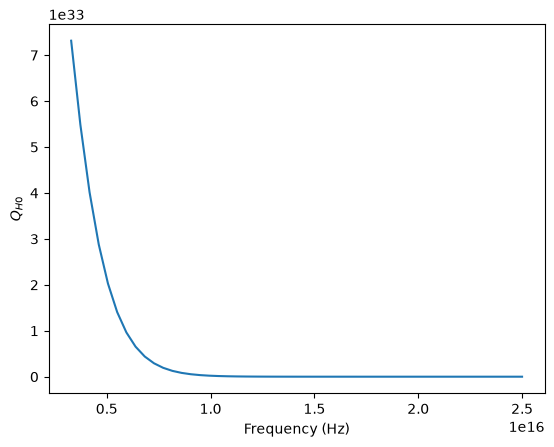

In [50]:
plt.plot(nu_arr, Q_H0_arr)
plt.xlabel(r'Frequency (Hz)')
plt.ylabel(r'$Q_{H0}$')

In [51]:
nu_max_arr = np.linspace(10 ** 16, 2.5 * 10 ** (16))
Romb_Strom_test_arr = np.zeros_like(nu_max_arr)

for i in range(len(nu_max_arr)):
    Romb_Strom_test_arr[i] = Romb_general(nu_min, nu_max_arr[i], 12, Q_H0_Int, 1)[0][12]

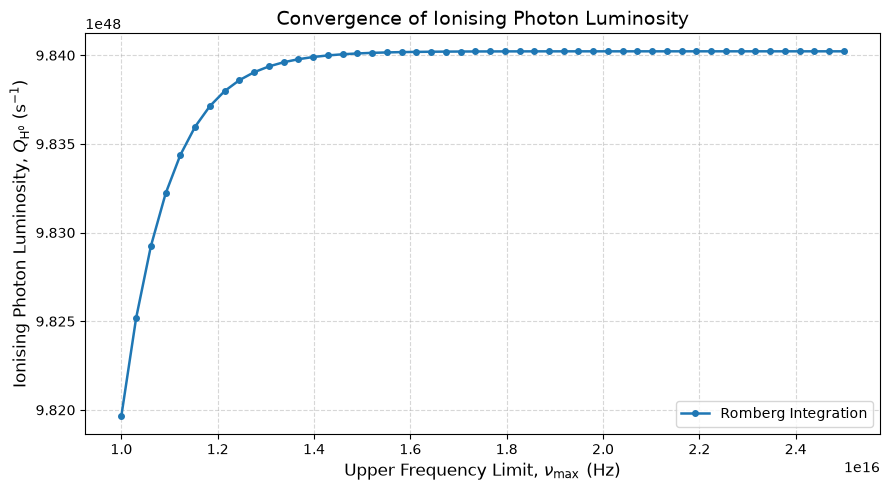

In [60]:
# Plot convergence of Romberg integration with increasing upper frequency limit
plt.figure(figsize=(9, 5))

plt.plot(
    nu_max_arr,
    Romb_Strom_test_arr,
    marker='o',
    markersize=4,
    linewidth=1.8,
    label='Romberg Integration'
)

# Plot formatting
plt.xlabel(r'Upper Frequency Limit, $\nu_{\max}$ (Hz)', fontsize=12)
plt.ylabel(r'Ionising Photon Luminosity, $Q_{\mathrm{H^0}}$ (s$^{-1}$)', fontsize=12)
plt.title('Convergence of Ionising Photon Luminosity', fontsize=14)

plt.ticklabel_format(axis='both', style='sci', scilimits=(0, 0))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=10)

plt.tight_layout()
plt.show()

In [53]:
nu_max_val = 1.6 * 10 ** 16 # Based on where the above plot plateus

In [54]:
N_val = 12

Q_H0_Romb_Matrix = Romb_general(nu_min, nu_max_val, N_val, Q_H0_Int, 1)

Q_H0_Final_val = Q_H0_Romb_Matrix[0, N_val]

In [55]:
def Strom_Radius(Q_H0_val): # in cm
    alpha_B = 3.5 * 10 ** (-13) # cm^3 / s
    n_H = 10 # cm^-3
    return (3 * Q_H0_val / (4 * np.pi * n_H ** 2 * alpha_B)) ** (1 / 3)

In [59]:
Strom_Radius(Q_H0_Final_val) / (1.5 * 10 ** (13)) * 4.85 * 10 ** (-6)

np.float64(13.140120554765318)

In [58]:
Q_H0_Romb_Matrix

array([[4.64975064e+49, 1.57521120e+49, 1.00482267e+49, 9.79790887e+48,
        9.83930146e+48, 9.84018730e+48, 9.84018503e+48, 9.84018502e+48,
        9.84018502e+48, 9.84018502e+48, 9.84018502e+48, 9.84018502e+48,
        9.84018502e+48],
       [2.34384606e+49, 1.04047196e+49, 9.80182009e+48, 9.83913977e+48,
        9.84018643e+48, 9.84018503e+48, 9.84018502e+48, 9.84018502e+48,
        9.84018502e+48, 9.84018502e+48, 9.84018502e+48, 9.84018502e+48,
        0.00000000e+00],
       [1.36631548e+49, 9.83950131e+48, 9.83855665e+48, 9.84018234e+48,
        9.84018503e+48, 9.84018502e+48, 9.84018502e+48, 9.84018502e+48,
        9.84018502e+48, 9.84018502e+48, 9.84018502e+48, 0.00000000e+00,
        0.00000000e+00],
       [1.07954147e+49, 9.83861569e+48, 9.84015694e+48, 9.84018502e+48,
        9.84018502e+48, 9.84018502e+48, 9.84018502e+48, 9.84018502e+48,
        9.84018502e+48, 9.84018502e+48, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00],
       [1.00778154e+49, 9.84006061e+

# Exercise 5a

In [36]:
#x_arr = [x_1, x_1 + h, x_1 + 2h, ..., x_1 + (n-1)h=x_n]

def Cub_Spl(x_arr, y_arr):
    h_arr = np.diff(x_arr)
    b_arr = np.zeros(len(x_arr))

    k_arr = np.zeros_like(b_arr)

    # matrix * b_arr = k_arr
    dim = len(h_arr) + 1
    matrix = np.zeros((dim, dim))

    matrix[0,0] = 1
    matrix[dim - 1, dim - 1] = 1

    # Evaluating matrix elements
    for i in range(dim):
        for j in range(dim):
            if (i == 0) or (i == dim - 1):
                continue
            elif (i == j):
                matrix[i, j] = 2 * (h_arr[i - 1] + h_arr[i])
            elif (i == j + 1):
                matrix[i, j] = h_arr[i - 1]
            elif (i == j - 1):
                matrix[i, j] = h_arr[i]
            else:
                continue

    # Evaluating k_arr
    for i in range(dim):
        if (i == 0) or (i == dim - 1):
            continue
        else:
            k_arr[i] = 3 * ((y_arr[i + 1] - y_arr[i]) / (h_arr[i]) - (y_arr[i] - y_arr[i - 1]) / h_arr[i - 1])

    k_arr = k_arr.reshape(-1, 1)

    # Inverting matrix:
    matrix_inv = np.linalg.inv(matrix)

    # Multiplying inverse matrix with k_arr:

    b_arr = np.dot(matrix_inv, k_arr)

    b_arr = b_arr.flatten()

    # defining other constants

    a_arr = np.zeros(len(b_arr) - 1)
    c_arr = np.zeros(len(b_arr) - 1)

    for i in range(dim - 1):
        a_arr[i] = (y_arr[i + 1] - y_arr[i]) / h_arr[i] - h_arr[i] / 3 * (2 * b_arr[i] + b_arr[i + 1])
        c_arr[i] = (b_arr[i + 1] - b_arr[i]) / (3 * h_arr[i])

    # Define sub-interval integrals

    Int_Ci_arr = np.zeros(len(b_arr) - 1)

    for i in range(dim - 1):
        Int_Ci_arr[i] = y_arr[i] * (x_arr[i + 1] - x_arr[i]) + a_arr[i] / 2 * (x_arr[i + 1] - x_arr[i]) ** 2 + b_arr[i] / 3 * (x_arr[i + 1] - x_arr[i]) ** 3 + c_arr[i] / 4 * (x_arr[i + 1] - x_arr[i]) ** 4

    return np.sum(Int_Ci_arr)

In [37]:
n_arr = np.array([2, 4, 8, 16, 32, 64, 128, 256])

x_arrays_arr = []
y_arrays_arr = []

a = 0
b = np.pi / 2

for i in range(len(n_arr)):
    x_arr = np.linspace(a, b, n_arr[i] + 1)
    y_arr = np.sin(2 * x_arr)

    x_arrays_arr.append(x_arr)
    y_arrays_arr.append(y_arr)

In [38]:
Cub_Int_arr = np.zeros(len(y_arrays_arr))
Cub_Err_arr = np.zeros_like(Cub_Int_arr)
Cub_Rat_arr = np.zeros(len(Cub_Int_arr) - 1)

True_val_sin = 1

for i in range(len(Cub_Int_arr)):
    Cub_Int_arr[i] = Cub_Spl(x_arrays_arr[i], y_arrays_arr[i])
    Cub_Err_arr[i] = True_val_sin - Cub_Int_arr[i]

for j in range(len(Cub_Int_arr) - 1):
    Cub_Rat_arr[j] = Cub_Err_arr[j] / Cub_Err_arr[j + 1]

In [39]:
print(Cub_Int_arr, Cub_Err_arr, Cub_Rat_arr)

[0.9817477  0.99934671 0.99996512 0.99999791 0.99999987 0.99999999
 1.         1.        ] [1.82522958e-02 6.53290114e-04 3.48809551e-05 2.09291584e-06
 1.29467596e-07 8.07087797e-09 5.04104536e-10 3.15014681e-11] [27.93903559 18.72913491 16.66620055 16.16555734 16.04132736 16.01032602
 16.00257278]


In [40]:
x_arr = np.linspace(0, np.pi, 1000)
y_arr = np.sin(x_arr)

Cub_Spl(x_arr, y_arr)

np.float64(1.9999999999997284)

# Exercise 5b

In [41]:
# Compute the integral of f(x)g(x)dx from a to b using n intervals.
# our function to be integrated, f(x)=1:
def f(x):
    return np.ones(len(x))
    
# weights for weighting function g(x)=sin(x):
def w_sin(xl,xr,dx,xm):
    G = (np.cos(xl)-np.cos(xr))/dx
    H = ((np.sin(xr)-np.sin(xl))/dx*2.-(np.cos(xr)+np.cos(xl)))/dx
    return G,H

# weights for weighting function g(x)=1 (cf. trapezoid integration):
def w_1(xl,xr,dx,xm):
    G = np.ones(len(dx))
    H = np.zeros(len(dx))
    return G,H

def weights(xl,xr,g):
    dx = xr-xl
    xm = (xr+xl)*.5
    G,H = g(xl,xr,dx,xm)
    Wm = dx*(G-H)*.5
    Wp = dx*(G+H)*.5
    return Wm,Wp

def integrate(a,b,n,f,g):
    x = np.array(range(n+1)) * (b-a)/n + a
    xl = x[0:n] # left sides of intervals
    xr = x[1:n+1] # right sides of intervals
    Wm,Wp = weights(xl,xr,g)
    return sum(f(xl)*Wm + f(xr)*Wp)

In [42]:
a = 0. # lower bound of integration interval
b = .5*np.pi # upper bound of integration interval
n = 7 # number of intervals
# integrate 1*sin(x)dx (f=1, g=sin)
area = integrate(a,b,n,f,w_sin)
print("integral from",a,"to",b,"is",area)
# switch f and g, corresponds to trapezoid:
area = integrate(a,b,n,np.sin,w_1)
print("integral from",a,"to",b,"is",area)

integral from 0.0 to 1.5707963267948966 is 1.0
integral from 0.0 to 1.5707963267948966 is 0.9958002136775372


In [43]:
a = 0. # lower bound of integration interval
b = np.pi # upper bound of integration interval
n = 7 # number of intervals
# integrate 1*sin(x)dx (f=1, g=sin)
area = integrate(a,b,n,f,w_sin)
print("integral from",a,"to",b,"is",area)
# switch f and g, corresponds to trapezoid:
area = integrate(a,b,n,np.sin,w_1)
print("integral from",a,"to",b,"is",area)

integral from 0.0 to 3.141592653589793 is 2.0
integral from 0.0 to 3.141592653589793 is 1.9663166787658923


In [44]:
# Compute the integral of f(x)g(x)dx from a to b using n intervals.
# our function to be integrated, f(x)=1:
def f1(x):
    return x
    
# weights for weighting function g(x)=sin(x):
def w_ex(xl,xr,dx,xm):
    G = (np.e ** (xr) - np.e ** (xl)) / dx
    H = (np.e ** xl + np.e ** xr + 2 / dx * (np.e ** xl - np.e ** xr))/dx
    return G,H

In [45]:
a = 0. # lower bound of integration interval
b = 1 # upper bound of integration interval
n = 7 # number of intervals
# integrate 1*sin(x)dx (f=1, g=sin)
area = integrate(a,b,n,f1,w_ex)
print("integral from",a,"to",b,"is",area)

integral from 0.0 to 1 is 1.0
